In [11]:
 # Kenya case study
# Reads: ../data/clean_joined.csv 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [12]:
sns.set_theme(style="whitegrid")

In [13]:
# loading  load the joined table and pick out Kenya
df = pd.read_csv("../data/clean_joined.csv")
kenya = df[df["Entity"] == "Kenya"].set_index("Year")
print("Kenya rows:", len(kenya), "| years", kenya.index.min(), "to", kenya.index.max())

Kenya rows: 73 | years 1950 to 2022


# Kenya next to the typical country

In [14]:
#working out the typical country (the median) in every year, to compare Kenya with
typical = df.groupby("Year")[["gdp_pc", "life_exp", "child_mort"]].median()

compare = kenya[["gdp_pc", "life_exp", "child_mort"]].join(typical, lsuffix="_kenya", rsuffix="_typical")

# I look at Kenya next to the typical country in a few years
compare.loc[[1960, 1990, 2000, 2019]].round(1)

,gdp_pc_kenya,life_exp_kenya,child_mort_kenya,gdp_pc_typical,life_exp_typical,child_mort_typical
Year,,,,,,
1960,1157.0,48.5,19.7,3148.0,53.2,15.5
1990,1780.0,58.3,10.1,5742.0,67.9,4.7
2000,1914.9,56.1,9.5,6593.5,70.2,3.1
2019,3207.3,62.9,4.3,12349.7,73.8,1.6


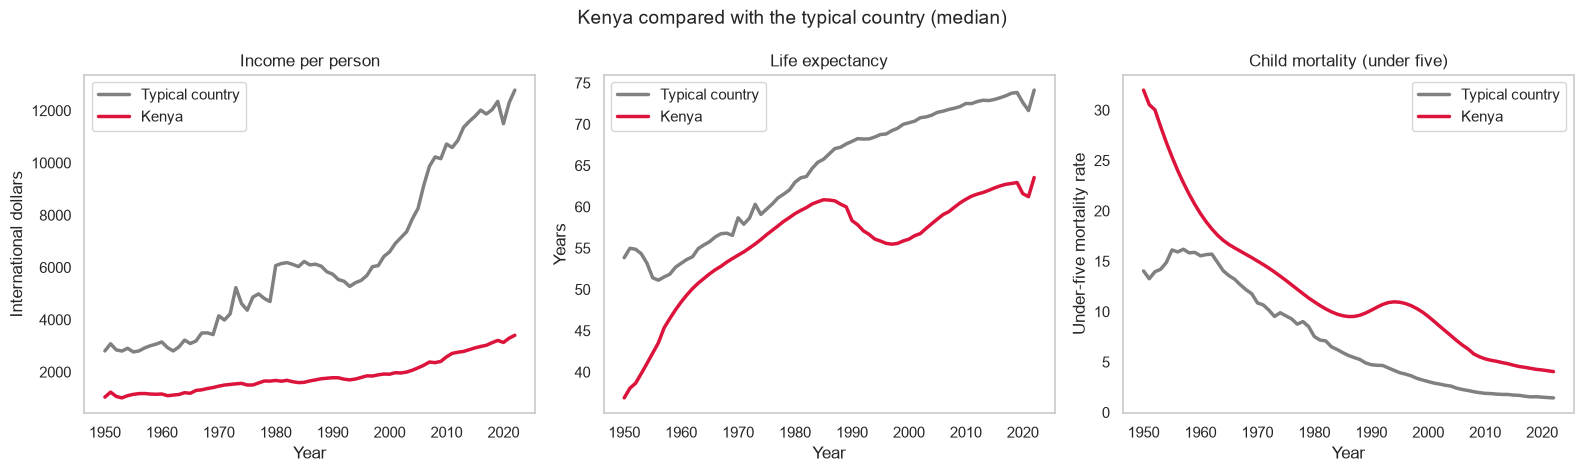

In [15]:
# Chart 1: Kenya next to the typical country, for income, life expectancy and child mortality
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

axes[0].plot(compare.index, compare["gdp_pc_typical"], color="gray", linewidth=2.5, label="Typical country")
axes[0].plot(compare.index, compare["gdp_pc_kenya"], color="crimson", linewidth=2.5, label="Kenya")
axes[0].set_title("Income per person")
axes[0].set_ylabel("International dollars")

axes[1].plot(compare.index, compare["life_exp_typical"], color="gray", linewidth=2.5, label="Typical country")
axes[1].plot(compare.index, compare["life_exp_kenya"], color="crimson", linewidth=2.5, label="Kenya")
axes[1].set_title("Life expectancy")
axes[1].set_ylabel("Years")

axes[2].plot(compare.index, compare["child_mort_typical"], color="gray", linewidth=2.5, label="Typical country")
axes[2].plot(compare.index, compare["child_mort_kenya"], color="crimson", linewidth=2.5, label="Kenya")
axes[2].set_title("Child mortality (under five)")
axes[2].set_ylabel("Under-five mortality rate")

for ax in axes:
    ax.set_xlabel("Year")
    ax.legend()
    ax.grid(False)
plt.suptitle("Kenya compared with the typical country (median)", fontsize=14)
plt.tight_layout()
plt.show()

# what would we expect for Kenya's income?

In [16]:
# What life expectancy would I expect for Kenya, given its income each year?
# drawing  a trend line for all countries in that year, then read off Kenya's income
expected = []
for year in compare.index:
    d = df[df["Year"] == year]
    slope, intercept = np.polyfit(d["log_gdp"], d["life_exp"], 1)
    expected.append(slope * np.log(compare.loc[year, "gdp_pc_kenya"]) + intercept)

compare["life_exp_expected"] = expected
compare["gap"] = compare["life_exp_kenya"] - compare["life_exp_expected"]

print("Years when Kenya was above what its income predicts:", int((compare["gap"] > 0).sum()), "of", len(compare))
print(f"Biggest shortfall: {compare['gap'].min():.1f} years in {compare['gap'].idxmin()}")
print(f"Biggest lead: {compare['gap'].max():.1f} years in {compare['gap'].idxmax()}")
print(f"2019 gap: {compare.loc[2019, 'gap']:.1f} years")

Years when Kenya was above what its income predicts: 38 of 73
Biggest shortfall: -5.8 years in 1951
Biggest lead: 7.9 years in 1984
2019 gap: -2.7 years


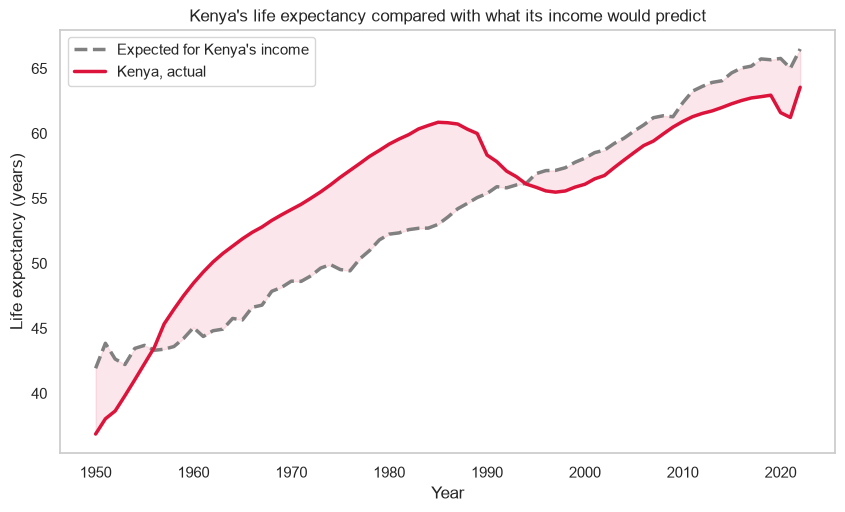

In [17]:
# Chart 2: Kenya's actual life expectancy next to what its income would predict
plt.figure(figsize=(10, 5.5))
plt.plot(compare.index, compare["life_exp_expected"], color="gray", linewidth=2.5, linestyle="--", label="Expected for Kenya's income")
plt.plot(compare.index, compare["life_exp_kenya"], color="crimson", linewidth=2.5, label="Kenya, actual")
plt.fill_between(compare.index, compare["life_exp_kenya"], compare["life_exp_expected"], color="crimson", alpha=0.1)
plt.title("Kenya's life expectancy compared with what its income would predict")
plt.xlabel("Year")
plt.ylabel("Life expectancy (years)")
plt.legend()
plt.grid(False)
plt.show()

# countries with a similar income

In [18]:
# Which countries had an income closest to Kenya's in 2019, and how did they do?
d2019 = df[df["Year"] == 2019].copy()
kenya_log = d2019.loc[d2019["Entity"] == "Kenya", "log_gdp"].iloc[0]
d2019["distance"] = (d2019["log_gdp"] - kenya_log).abs()
peers = d2019.sort_values("distance").head(9)[["Entity", "gdp_pc", "life_exp", "child_mort"]].round(1)
peers = peers.sort_values("life_exp", ascending=False).reset_index(drop=True)
peers

,Entity,gdp_pc,life_exp,child_mort
0,Syria,3385.4,71.0,2.5
1,Nepal,2953.6,69.3,3.1
2,Mauritania,3659.1,67.6,4.3
3,Tanzania,2894.6,66.0,4.6
4,Djibouti,3437.0,64.4,5.8
5,Kenya,3207.3,62.9,4.3
6,Zambia,3466.2,62.9,5.4
7,Cameroon,2832.1,61.7,7.7
8,Cote d'Ivoire,3703.1,60.3,7.5


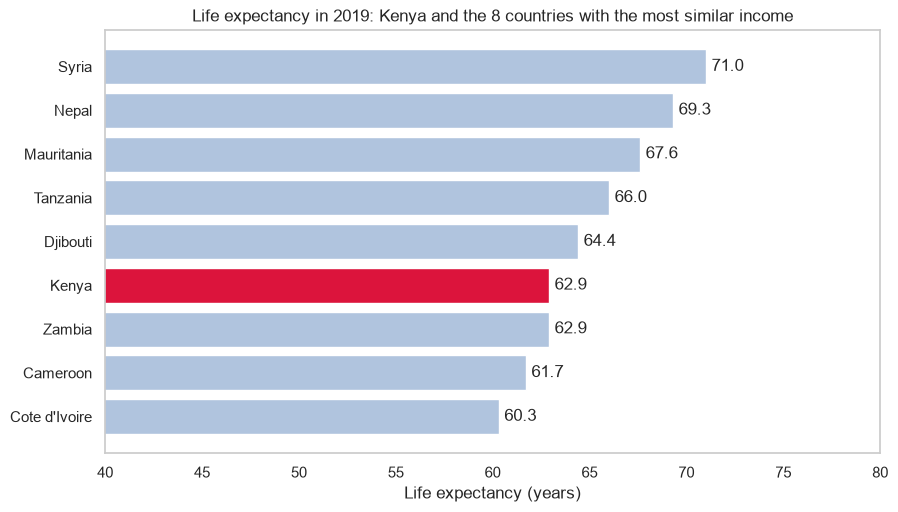

In [19]:
# Chart 3: Kenya and the countries with the most similar income, 2019
colors = ["crimson" if name == "Kenya" else "lightsteelblue" for name in peers["Entity"]]

plt.figure(figsize=(10, 5.5))
plt.barh(peers["Entity"], peers["life_exp"], color=colors)
for i, value in enumerate(peers["life_exp"]):
    plt.text(value + 0.3, i, f"{value:.1f}", va="center")
plt.gca().invert_yaxis()
plt.xlim(40, 80)
plt.title("Life expectancy in 2019: Kenya and the 8 countries with the most similar income")
plt.xlabel("Life expectancy (years)")
plt.grid(False)
plt.show()

In [20]:
#  printing out  the numbers I will use in my write-up
k = compare.loc[2019]
print(f"Kenya 2019: income {k['gdp_pc_kenya']:,.0f} dollars, life expectancy {k['life_exp_kenya']:.1f} years, child mortality {k['child_mort_kenya']:.2f}")
print(f"Typical country 2019: income {k['gdp_pc_typical']:,.0f} dollars, life expectancy {k['life_exp_typical']:.1f} years, child mortality {k['child_mort_typical']:.2f}")
rank = int(peers[peers["Entity"] == "Kenya"].index[0]) + 1
print(f"Among these 9 countries of similar income, Kenya is number {rank} for life expectancy")
print(f"Kenya's life expectancy rose {compare.loc[2019, 'life_exp_kenya'] - compare.loc[1960, 'life_exp_kenya']:.1f} years from 1960 to 2019")

Kenya 2019: income 3,207 dollars, life expectancy 62.9 years, child mortality 4.27
Typical country 2019: income 12,350 dollars, life expectancy 73.8 years, child mortality 1.56
Among these 9 countries of similar income, Kenya is number 6 for life expectancy
Kenya's life expectancy rose 14.5 years from 1960 to 2019


What I got on your data:

## Kenya has 73 rows (1950 to 2022).
## In 2019 Kenya had an income of 3,207 dollars (typical country 12,350), life expectancy of 62.9 years (typical 73.8), and child mortality of 4.27 (typical 1.56).
## Its life expectancy rose 14.5 years from 1960 to 2019.
## It was above what its income predicts in 38 of 73 years. The biggest lead was +7.9 years in 1984, and the biggest shortfall was -5.8 years in 1951. In 2019 it sat 2.7 years below.
## The chart shows Kenya ahead of its income-predicted line from the late 1950s until about the early 1990s, then falling below it. The data shows when this happened, not why, so don't state a cause.
## Among the 9 countries with the closest income in 2019, Kenya ranks 6th for life expectancy (Syria 71.0 at the top, Cote d'Ivoire 60.3 at the bottom).
## "Typical country" means the median across all countries in that year.